# c9 · Step 9: Learning rate again, and the final model

The learning rate was tuned in c6 on the small, unregularised model. Depth, width, augmentation and weight decay
all shift the best value, so it is re-checked on the final configuration: ×⅓, ×1 and ×3 of the current value.
Then the **final model** is trained.

**Which run is "the" final model?** Picking the best of several seeds on val would be cherry-picking. So the
rule is fixed in advance: the run with **seed 1738** is the final model, and the other seeds only show how much
retraining varies.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run, build_model, RESULTS, CKPT
from lib.report import run_seeds, compare, pick, SEEDS3, curve_test
from lib.evaluation import bootstrap_ci, wilson
from lib.models import n_params, n_conv_layers
from lib.data import ARTIFACTS, CLASSES, SEED
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
OPTIM = json.loads((ARTIFACTS / "optim.json").read_text())
REG = json.loads((ARTIFACTS / "reg.json").read_text())
ARCH = {k: tuple(v) if isinstance(v, list) else v for k, v in REG["arch"].items()}
SEEDS = SEEDS3 if REG["winner"] == "small" else SEEDS3[:2]
CUR = replace(Config(exp="c9", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **{**INPUT, **OPTIM, **ARCH,
              "aug": REG["aug"], "optimizer": REG["optimizer"], "weight_decay": REG["weight_decay"], "dropout": REG["dropout"]})
print(CUR)

Config(exp='c9', name='x', mode='gray', resize='crop', size=128, probe=False, normalize='per_image', train_frac=1.0, train_n=0, widths=(16, 32, 64, 128), depths=(1, 1, 1, 1), kernel=5, stem_kernel=5, block='basic', norm=True, residual=True, downsample='avgpool', dropout=0.0, optimizer='adam', lr=0.03, weight_decay=0.0, batch_size=128, schedule='none', loss='focal', sampler='none', epochs=200, patience=20, monitor='val_bal_acc', aug='geometric', seed=1738, extra={})


## 1. Learning rate re-check

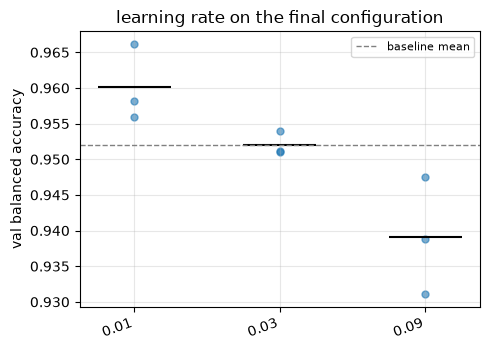

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0.01,0.9601,0.0054,3.0,0.0080,0.0505,0.9565,0.9965,0.9549,81.0000,832308.0,1.0781
0.03,0.9521,0.0017,3.0,0.0000,0.0505,0.9451,0.9960,0.9722,55.3333,832308.0,1.0661
0.09,0.9391,0.0082,3.0,-0.0129,0.0505,0.9319,0.9946,0.9583,60.3333,832308.0,1.0614


{'slope_per_decade': -0.0219, 'slope_ci': (np.float64(-0.03304496422760173), np.float64(-0.010852938663831422)), 'p_linear': 0.0023, 'p_quadratic': 0.5711, 'has_shape': True, 'best': 0.01, 'best_at_edge': True}
final learning rate: 0.009999999999999998


In [2]:
lr0 = CUR.lr
# the x1 runs are named "final" so that, if the LR stays, they are reused as the final model's runs
lr_runs = {lr0 * f: run_seeds(replace(CUR, name="final" if f == 1 else f"lr{lr0 * f:.2g}", lr=lr0 * f), SEEDS) for f in [1 / 3, 1, 3]}
t = compare({f"{k:.2g}": v for k, v in lr_runs.items()}, f"{lr0:.2g}", "learning rate on the final configuration"); display(t)
ct = curve_test(lr_runs)   # same rule as c6 for ordered settings
print({k: (round(float(v), 4) if not isinstance(v, (dict, tuple, bool)) else v) for k, v in ct.items() if k != "means"})
LR = float(ct["best"])
CUR = replace(CUR, lr=LR); print("final learning rate:", LR)

_TODO lr_

## 2. The final model

In [3]:
final_runs = run_seeds(replace(CUR, name="final" if LR == lr0 else f"final_lr{LR:.2g}"), SEEDS3)
FINAL = final_runs[0]; assert FINAL["config"]["seed"] == SEED
net = build_model(CUR, 3 if CUR.mode == "rgb" else 1)
print(f"final model: {n_conv_layers(net)} conv layers, {n_params(net):,} parameters, {FINAL['sec_per_epoch']:.1f} s/epoch on {FINAL['device']}")
rows = {f"seed {r['config']['seed']}": {"bal_acc": r["val"]["bal_acc"], "macro_f1": r["val"]["macro_f1"],
        "tumor_auc": r["val"]["tumor_auc"], **{f"rec {c}": r["val"]["recall"][c] for c in CLASSES},
        "best_epoch": r["best_epoch"]} for r in final_runs}
S = pd.DataFrame(rows).T; S.loc["mean ± sd"] = [f"{S[c].mean():.3f} ± {S[c].std():.3f}" for c in S.columns]
display(S)

final model: 9 conv layers, 832,308 parameters, 1.1 s/epoch on cuda


C:\Users\vikto\AppData\Local\Temp\ipykernel_20564\1036243526.py:8: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype float64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  S = pd.DataFrame(rows).T; S.loc["mean ± sd"] = [f"{S[c].mean():.3f} ± {S[c].std():.3f}" for c in S.columns]


,bal_acc,macro_f1,tumor_auc,rec glioma,rec meningioma,rec no_tumor,rec pituitary,best_epoch
seed 1738,0.952435,0.939874,0.996632,0.9231,0.9259,0.9896,0.9712,46.0
seed 1739,0.958912,0.955585,0.99632,0.9423,0.9398,0.9583,0.9952,49.0
seed 1740,0.968015,0.966157,0.99666,0.9712,0.9722,0.9479,0.9808,65.0
mean ± sd,0.960 ± 0.008,0.954 ± 0.013,0.997 ± 0.000,0.946 ± 0.024,0.946 ± 0.024,0.965 ± 0.022,0.982 ± 0.012,53.333 ± 10.214


FINAL (seed 1738) on clean val: balanced accuracy 0.952  [95% CI 0.935, 0.966]
  recall glioma      0.949  [0.918, 0.968]  (296/312)
  recall meningioma  0.907  [0.861, 0.939]  (196/216)
  recall no_tumor    0.958  [0.898, 0.984]  (92/96)
  recall pituitary   0.990  [0.966, 0.997]  (206/208)


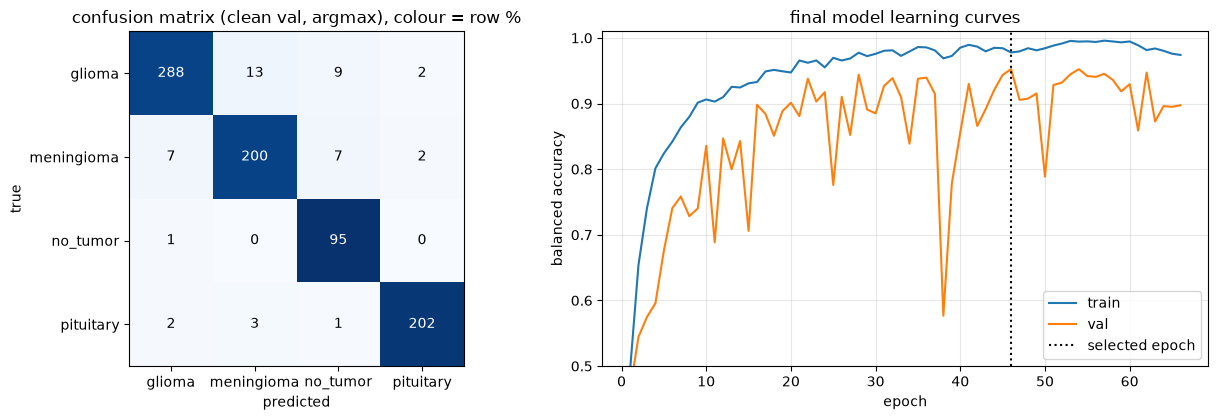

In [4]:
d = np.load(RESULTS / "c9" / f"final_s{SEED}_val.npz"); y, prob = d["y"], d["prob"]; pred = prob.argmax(1)
lo, hi = bootstrap_ci(y, pred)
print(f"FINAL (seed {SEED}) on clean val: balanced accuracy {FINAL['val']['bal_acc']:.3f}  [95% CI {lo:.3f}, {hi:.3f}]")
for i, c in enumerate(CLASSES):
    k, n = int(((pred == i) & (y == i)).sum()), int((y == i).sum()); l, h = wilson(k, n)
    print(f"  recall {c:11s} {k / n:.3f}  [{l:.3f}, {h:.3f}]  ({k}/{n})")
cm = np.array(FINAL["val"]["confusion"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
ax[0].set(xticks=range(4), yticks=range(4), xticklabels=CLASSES, yticklabels=CLASSES, xlabel="predicted", ylabel="true",
          title="confusion matrix (clean val, argmax), colour = row %")
h = pd.DataFrame(FINAL["history"])
ax[1].plot(h.epoch, h.train_bal_acc, label="train"); ax[1].plot(h.epoch, h.val_bal_acc, label="val")
ax[1].axvline(FINAL["best_epoch"], color="k", ls=":", label="selected epoch")
ax[1].set(xlabel="epoch", ylabel="balanced accuracy", title="final model learning curves", ylim=(0.5, 1.01)); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. How far did each step get us?
Mean val balanced accuracy of the chosen configuration after each step (3 seeds; 2 for deep runs).

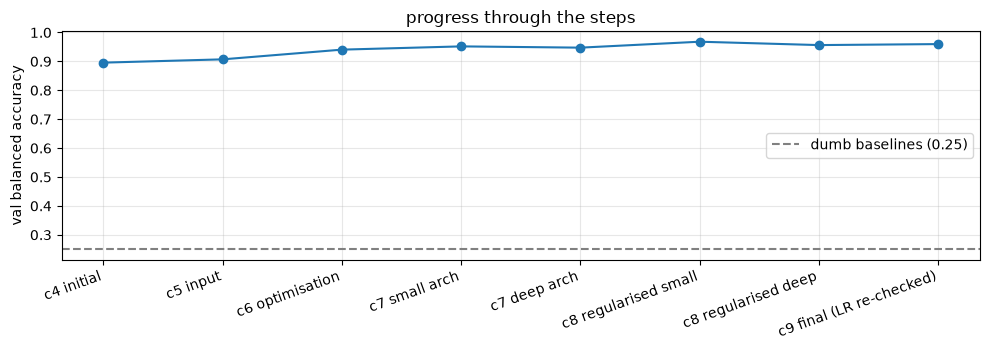

c4 initial                  0.8956
c5 input                    0.9070
c6 optimisation             0.9406
c7 small arch               0.9519
c7 deep arch                0.9475
c8 regularised small        0.9680
c8 regularised deep         0.9564
c9 final (LR re-checked)    0.9598
dtype: float64

In [5]:
from lib.report import sigma_seed
steps = json.loads((ARTIFACTS / "progress.json").read_text()) if (ARTIFACTS / "progress.json").exists() else {}
steps["c9 final (LR re-checked)"] = float(np.mean([r["val"]["bal_acc"] for r in final_runs]))
P = pd.Series(steps)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(range(len(P)), P.values, marker="o"); ax.set_xticks(range(len(P)), P.index, rotation=20, ha="right")
ax.axhline(0.25, color="grey", ls="--", label="dumb baselines (0.25)")
ax.set(ylabel="val balanced accuracy", title="progress through the steps"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show(); display(P.round(4))

_TODO final_

In [6]:
_ = (ARTIFACTS / "final.json").write_text(json.dumps({"config": FINAL["config"],
     "checkpoint": str((CKPT / "c9" / f"final_s{SEED}.pt").relative_to(CKPT.parent))}, indent=1))